# Convolução 1D: Projeto 1 (Sinais e Sistemas, 2ª Unidade)

Baseado no módulo `3_ Convolucion_1.ipynb` do curso (vídeo até 12:34).

Roteiro:
1. Convolução 1D: exemplo básico (conta feita à mão e pelo NumPy)
2. Filtro de média nos dados do motor (`3.data/Motor.csv`)
3. **Kernel de média maior**: o que muda ao aumentar o tamanho?
4. **Kernel gaussiano**: implementação e comparação com o kernel de média

## 1. Convolução 1D: exemplo básico

In [1]:
import numpy as np               # NumPy: vetores e a função de convolução (np.convolve)
import matplotlib.pyplot as plt  # Matplotlib: gráficos
import pandas as pd              # Pandas: leitura do arquivo CSV com os dados do motor

Tamanho do sinal de entrada: 7
Tamanho do kernel: 3


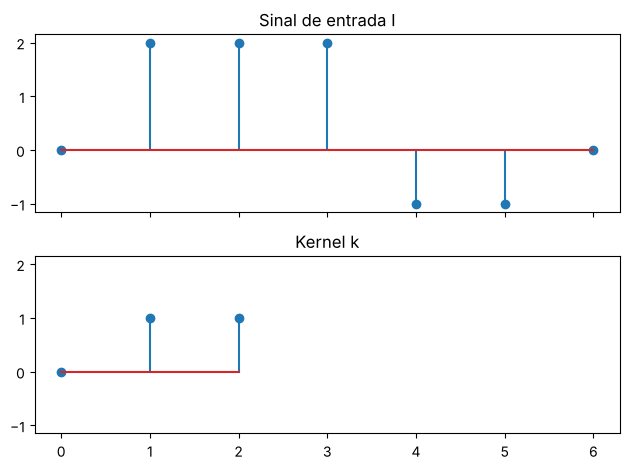

In [2]:
I = np.array([0, 2, 2, 2, -1, -1, 0])  # sinal de entrada I (7 amostras)
k = np.array([0, 1, 1])                # kernel de convolução k (3 amostras)

print('Tamanho do sinal de entrada:', len(I))  # mostra quantas amostras I tem
print('Tamanho do kernel:', len(k))            # mostra quantas amostras k tem

fig, axs = plt.subplots(2, sharex=True, sharey=True)  # figura com 2 gráficos empilhados, mesmos eixos
axs[0].stem(I)                                        # gráfico de hastes do sinal de entrada
axs[0].set_title('Sinal de entrada I')                # título do primeiro gráfico
axs[1].stem(k)                                        # gráfico de hastes do kernel
axs[1].set_title('Kernel k')                          # título do segundo gráfico
plt.tight_layout()                                    # ajusta os espaços para os títulos não se sobreporem
plt.show()                                            # exibe a figura

A convolução discreta é $S[n] = \sum_m I[m]\,k[n-m]$: o kernel é **refletido** e **desliza** sobre o sinal,
e em cada posição os produtos das amostras sobrepostas são somados.

Com $k = [0, 1, 1]$, isso vira $S[n] = I[n-1] + I[n-2]$. O resultado tem `len(I) + len(k) - 1 = 9` amostras.

Tamanho de S (len(I)+len(k)-1): 9
S = [ 0  0  2  4  4  1 -2 -1  0]
S manual = [ 0.  0.  2.  4.  4.  1. -2. -1.  0.]


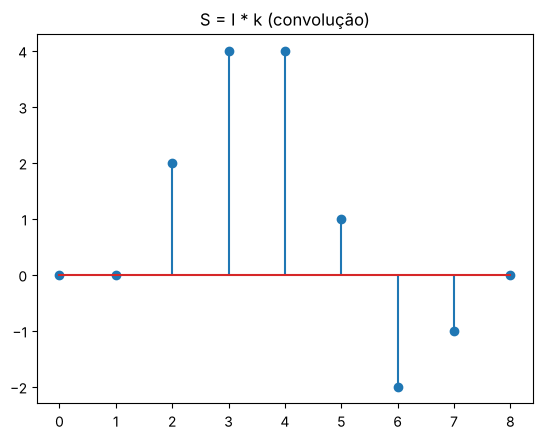

In [3]:
S = np.convolve(I, k)  # convolução completa (mode='full', o padrão do NumPy)

print('Tamanho de S (len(I)+len(k)-1):', len(S))  # confere o tamanho: 7 + 3 - 1 = 9
print('S =', S)                                   # mostra os valores da convolução

S_manual = np.zeros(len(I) + len(k) - 1)  # vetor de zeros para a convolução feita "à mão"
for n in range(len(S_manual)):            # percorre cada posição n da saída
    for m in range(len(I)):               # percorre cada amostra m do sinal de entrada
        if 0 <= n - m < len(k):           # só soma quando o índice do kernel existe
            S_manual[n] += I[m] * k[n - m]  # soma do produto I[m]*k[n-m] (definição da convolução)
print('S manual =', S_manual)             # deve ser igual ao resultado do NumPy

plt.stem(S)                        # gráfico de hastes do resultado
plt.title('S = I * k (convolução)')  # título
plt.show()                         # exibe a figura

## 2. Filtro de média nos dados do motor

In [4]:
Dados = pd.read_csv('3.data/Motor.csv')  # lê o CSV com as colunas Tiempo (s) e Amplitud (velocidade)
Dados.head()                             # mostra as 5 primeiras linhas para conferir os dados

,Tiempo,Amplitud
0,3.655582,0.00
1,3.716871,0.00
2,3.773982,5.06
3,3.835531,35.58
4,3.895979,62.75


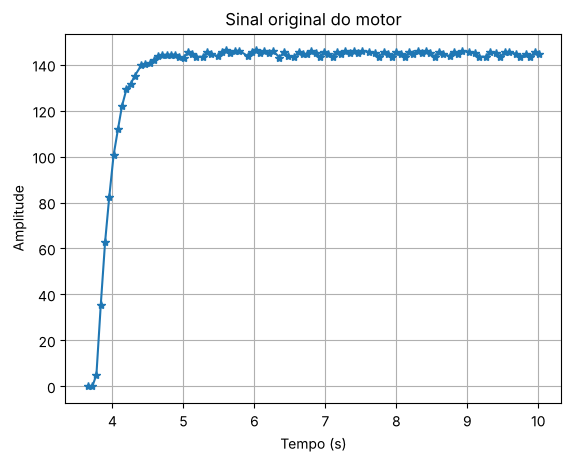

In [5]:
t = Dados['Tiempo'].to_numpy()    # vetor de tempo (eixo x)
I = Dados['Amplitud'].to_numpy()  # vetor do sinal do sensor: é a nossa entrada I

plt.plot(t, I, '-*')        # plota o sinal original, com '*' marcando cada amostra
plt.xlabel('Tempo (s)')     # rótulo do eixo x
plt.ylabel('Amplitude')     # rótulo do eixo y
plt.title('Sinal original do motor')  # título
plt.grid(True)              # liga a grade
plt.show()                  # exibe a figura

O **filtro de média** usa um kernel com todos os valores iguais e **soma 1**.
Cada amostra de saída vira a média das amostras vizinhas, o que suaviza o ruído sem mudar o nível do sinal.

Com `mode='same'`, a saída tem o mesmo tamanho da entrada. Nas **bordas**, porém, o kernel fica parcialmente
fora do sinal (o NumPy completa com zeros) e a média sai errada. Por isso as bordas são cortadas nos gráficos.

99 99 4


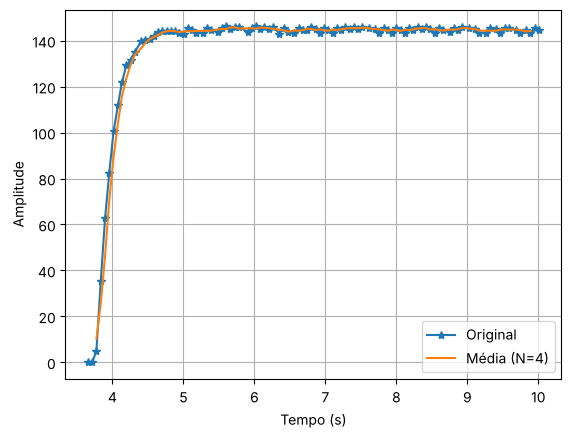

In [6]:
k_media4 = np.array([0.25, 0.25, 0.25, 0.25])  # kernel de média com 4 amostras (soma = 1), o mesmo do vídeo
S_media4 = np.convolve(I, k_media4, mode='same')  # convolução mantendo o tamanho da entrada
print(len(S_media4), len(I), len(k_media4))       # confere: saída e entrada com o mesmo tamanho

plt.plot(t, I, '-*', label='Original')                         # sinal original
plt.plot(t[2:-2], S_media4[2:-2], '-', label='Média (N=4)')  # sinal filtrado, sem as bordas
plt.xlabel('Tempo (s)')  # rótulo do eixo x
plt.ylabel('Amplitude')  # rótulo do eixo y
plt.legend()             # mostra a legenda
plt.grid(True)           # liga a grade
plt.show()               # exibe a figura

## 3. Kernel de média maior

Uma função `kernel_media(N)` gera um kernel de média de qualquer tamanho N: N valores iguais a 1/N.

Uso **tamanhos ímpares** (5, 11, 21) porque o kernel fica centrado: com tamanho par, o `mode='same'`
desloca a saída em meia amostra.

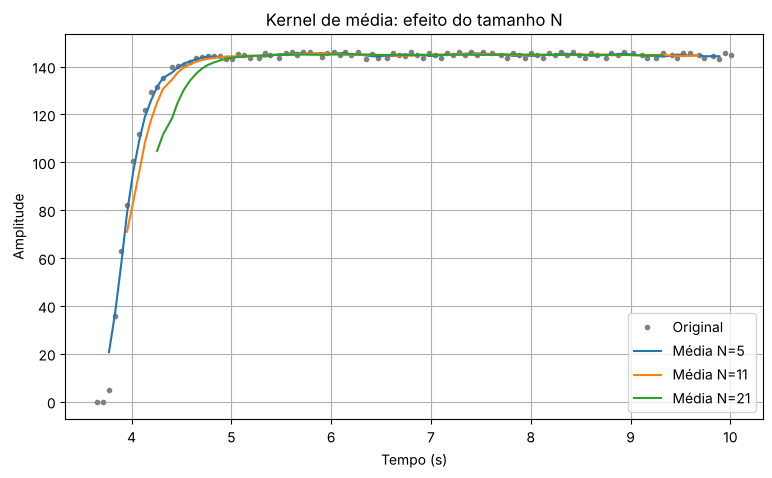

In [7]:
def kernel_media(N):          # função que cria um kernel de média de tamanho N
    return np.ones(N) / N     # N valores iguais a 1/N, então a soma é 1

def corta(N):                 # quantas amostras cortar em cada borda para um kernel de tamanho N
    return (N - 1) // 2       # metade do kernel: onde ele fica parcialmente fora do sinal

plt.figure(figsize=(9, 5))                  # figura maior para caber as curvas
plt.plot(t, I, '.', color='gray', label='Original')  # sinal original em pontos cinza
for N in [5, 11, 21]:                       # testa três tamanhos de kernel
    S = np.convolve(I, kernel_media(N), mode='same')  # filtra com o kernel de média de tamanho N
    c = corta(N)                            # amostras a descartar em cada borda
    plt.plot(t[c:-c], S[c:-c], label=f'Média N={N}')  # plota o resultado sem as bordas
plt.xlabel('Tempo (s)')      # rótulo do eixo x
plt.ylabel('Amplitude')      # rótulo do eixo y
plt.title('Kernel de média: efeito do tamanho N')  # título
plt.legend()                 # legenda
plt.grid(True)               # grade
plt.show()                   # exibe a figura

**Observação:** quanto **maior** o kernel, **mais suave** fica a saída (mais ruído é removido).
Em compensação, as variações rápidas (a subida do motor) ficam **arredondadas e atrasadas**, e perdemos mais amostras nas bordas.

## 4. Kernel gaussiano

**Sim, é possível.** Qualquer vetor pode ser kernel. O gaussiano usa os valores da curva
$g(x) = e^{-x^2 / (2\sigma^2)}$, com $x = -\frac{N-1}{2}, \dots, 0, \dots, \frac{N-1}{2}$.
Depois os valores são **normalizados para soma 1**, como no kernel de média.

Diferença: a média dá **o mesmo peso** a todos os vizinhos. A gaussiana dá **peso maior à amostra central**
e pesos cada vez menores às mais distantes. O $\sigma$ controla a "largura" do sino.

Kernel média    : [0.091 0.091 0.091 0.091 0.091 0.091 0.091 0.091 0.091 0.091 0.091]
Kernel gaussiano: [0.009 0.027 0.065 0.122 0.177 0.201 0.177 0.122 0.065 0.027 0.009]
Somas: 1.0 1.0


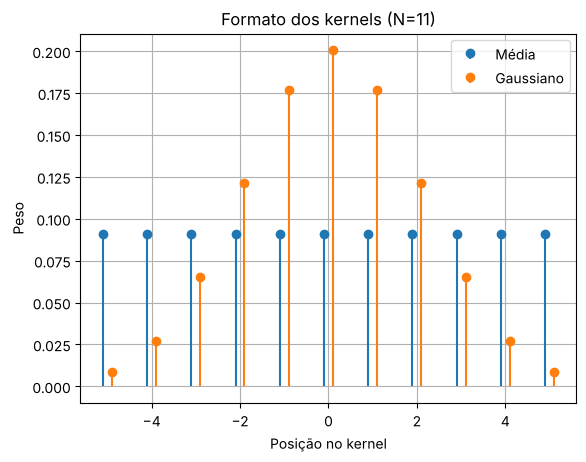

In [8]:
def kernel_gaussiano(N, sigma):           # cria um kernel gaussiano de tamanho N e desvio padrão sigma
    x = np.arange(N) - (N - 1) / 2        # posições centradas em zero, ex.: N=5 -> [-2,-1,0,1,2]
    g = np.exp(-x**2 / (2 * sigma**2))    # valores da curva gaussiana em cada posição
    return g / g.sum()                    # normaliza para a soma ser 1 (não muda o nível do sinal)

N = 11                                    # mesmo tamanho para os dois kernels (comparação justa)
k_med = kernel_media(N)                   # kernel de média de tamanho 11
k_gau = kernel_gaussiano(N, sigma=2)      # kernel gaussiano de tamanho 11 com sigma = 2

print('Kernel média    :', np.round(k_med, 3))  # mostra os pesos da média (todos iguais)
print('Kernel gaussiano:', np.round(k_gau, 3))  # mostra os pesos da gaussiana (maior no centro)
print('Somas:', k_med.sum(), k_gau.sum())       # confere que as duas somas são 1

x = np.arange(N) - (N - 1) // 2                     # eixo x centrado para o gráfico dos kernels
plt.stem(x - 0.1, k_med, linefmt='C0-', markerfmt='C0o', basefmt=' ', label='Média')     # hastes da média (um pouco à esquerda)
plt.stem(x + 0.1, k_gau, linefmt='C1-', markerfmt='C1o', basefmt=' ', label='Gaussiano') # hastes da gaussiana (um pouco à direita)
plt.title(f'Formato dos kernels (N={N})')  # título
plt.xlabel('Posição no kernel')            # rótulo do eixo x
plt.ylabel('Peso')                         # rótulo do eixo y
plt.legend()                               # legenda
plt.grid(True)                             # grade
plt.show()                                 # exibe a figura

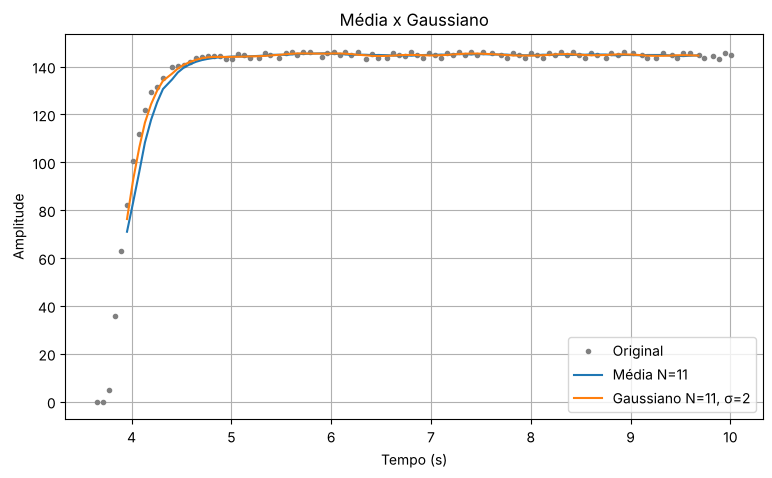

In [9]:
S_med = np.convolve(I, k_med, mode='same')  # sinal filtrado pela média
S_gau = np.convolve(I, k_gau, mode='same')  # sinal filtrado pela gaussiana
c = corta(N)                                # amostras de borda a descartar (5 de cada lado)

plt.figure(figsize=(9, 5))                                  # figura maior
plt.plot(t, I, '.', color='gray', label='Original')         # sinal original
plt.plot(t[c:-c], S_med[c:-c], label=f'Média N={N}')        # resultado da média
plt.plot(t[c:-c], S_gau[c:-c], label=f'Gaussiano N={N}, σ=2')  # resultado da gaussiana
plt.xlabel('Tempo (s)')      # rótulo do eixo x
plt.ylabel('Amplitude')      # rótulo do eixo y
plt.title('Média x Gaussiano')  # título
plt.legend()                 # legenda
plt.grid(True)               # grade
plt.show()                   # exibe a figura

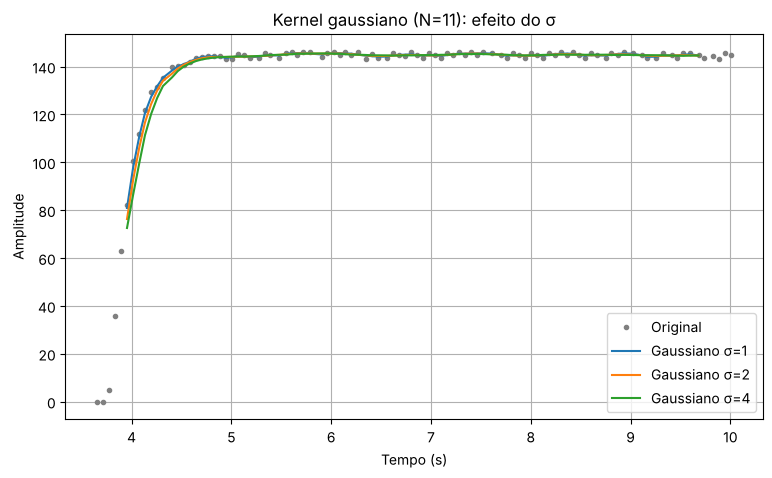

In [10]:
plt.figure(figsize=(9, 5))                                  # figura para variar o sigma
plt.plot(t, I, '.', color='gray', label='Original')         # sinal original
for sigma in [1, 2, 4]:                                     # três larguras de gaussiana
    S = np.convolve(I, kernel_gaussiano(N, sigma), mode='same')  # filtra com cada sigma
    plt.plot(t[c:-c], S[c:-c], label=f'Gaussiano σ={sigma}')     # plota sem as bordas
plt.xlabel('Tempo (s)')      # rótulo do eixo x
plt.ylabel('Amplitude')      # rótulo do eixo y
plt.title(f'Kernel gaussiano (N={N}): efeito do σ')  # título
plt.legend()                 # legenda
plt.grid(True)               # grade
plt.show()                   # exibe a figura

### Teste com ruído

O sinal do motor tem pouco ruído, então as diferenças acima são pequenas. Para elas ficarem visíveis,
somo ao sinal um **ruído aleatório** (desvio padrão 5) e filtro de novo com os dois kernels.

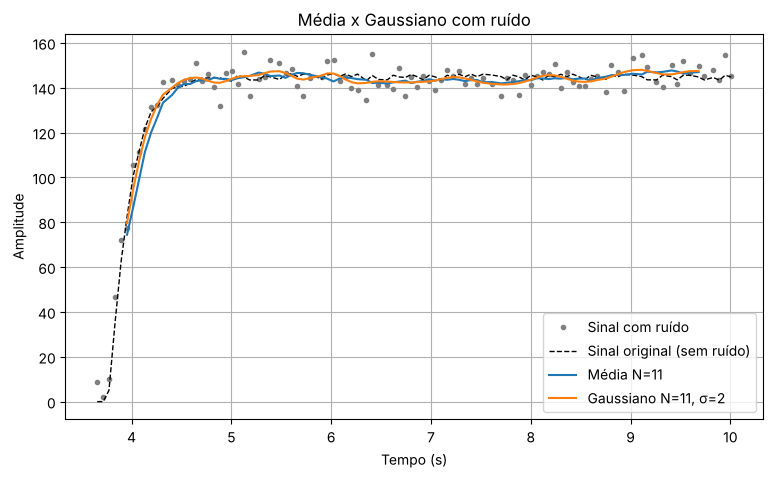

Erro RMS sem filtro: 4.89
Erro RMS média     : 3.20
Erro RMS gaussiano : 2.20


In [11]:
np.random.seed(0)                                   # semente fixa: o ruído sai igual em toda execução
I_ruido = I + np.random.normal(0, 5, len(I))        # sinal + ruído gaussiano (média 0, desvio 5)

S_med_r = np.convolve(I_ruido, k_med, mode='same')  # sinal ruidoso filtrado pela média
S_gau_r = np.convolve(I_ruido, k_gau, mode='same')  # sinal ruidoso filtrado pela gaussiana

plt.figure(figsize=(9, 5))                                     # figura maior
plt.plot(t, I_ruido, '.', color='gray', label='Sinal com ruído')  # sinal com ruído
plt.plot(t, I, 'k--', linewidth=1, label='Sinal original (sem ruído)')  # referência: sinal original
plt.plot(t[c:-c], S_med_r[c:-c], label=f'Média N={N}')         # resultado da média
plt.plot(t[c:-c], S_gau_r[c:-c], label=f'Gaussiano N={N}, σ=2')  # resultado da gaussiana
plt.xlabel('Tempo (s)')      # rótulo do eixo x
plt.ylabel('Amplitude')      # rótulo do eixo y
plt.title('Média x Gaussiano com ruído')  # título
plt.legend()                 # legenda
plt.grid(True)               # grade
plt.show()                   # exibe a figura

erro_med = np.sqrt(np.mean((S_med_r[c:-c] - I[c:-c])**2))  # erro RMS da média em relação ao sinal original
erro_gau = np.sqrt(np.mean((S_gau_r[c:-c] - I[c:-c])**2))  # erro RMS da gaussiana em relação ao sinal original
erro_sem = np.sqrt(np.mean((I_ruido[c:-c] - I[c:-c])**2))  # erro RMS sem filtrar (só o ruído)
print(f'Erro RMS sem filtro: {erro_sem:.2f}')   # quanto o ruído afasta o sinal do original
print(f'Erro RMS média     : {erro_med:.2f}')   # quanto sobra depois do filtro de média
print(f'Erro RMS gaussiano : {erro_gau:.2f}')   # quanto sobra depois do filtro gaussiano

## Conclusões

- **Convolução** = refletir o kernel, deslizar sobre o sinal e somar os produtos. A saída completa tem `len(I)+len(k)-1` amostras.
- **Kernel de média:** um kernel maior suaviza mais o ruído, mas arredonda e atrasa as variações rápidas e desperdiça mais amostras nas bordas.
- **Kernel gaussiano:** funciona como filtro passa-baixas, igual à média, mas com pesos maiores no centro.
  Com o **mesmo tamanho**, ele suaviza **menos** que a média e **preserva melhor** a forma do sinal (a subida do motor fica menos deformada).
  O **σ** ajusta a suavização: σ pequeno quase não filtra; σ grande se aproxima da média.
- **No teste com ruído**, a média deixa a parte constante um pouco mais lisa, mas deforma mais a subida.
  No total, a gaussiana fica mais próxima do sinal original (erro RMS menor).
- Nos dois casos, o kernel precisa ter **soma 1** para não alterar a amplitude do sinal.